# A3 - Learning to Summarize from Human Feedback
### SFT -> Reward Model -> PPO -> DPO, all written PyTorch

## 0. Setup

In [1]:
!pip -q install rouge-score gradio

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/rlhf"      # everything is saved here
CKPT = f"{BASE}/checkpoints"
RESULTS = f"{BASE}/results"
FIG = f"{RESULTS}/figures"
for d in [CKPT, RESULTS, FIG]:
    os.makedirs(d, exist_ok=True)
print(os.listdir(BASE))

Mounted at /content/drive
['results', 'project.zip', 'checkpoints']


In [3]:
import json, math, random, time
from functools import partial

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE, torch.cuda.get_device_name() if DEVICE == "cuda" else "")

cuda Tesla T4


# Task 1: Starter code, data, and the helper

## 1.1 Starter code (given by sir, Appendix A.2 - A.5, unchanged)

In [4]:
# sir code (A.2 config.py)
MODEL_NAME = "HuggingFaceTB/SmolLM2-135M"
SFT_DATA = "CarperAI/openai_summarize_tldr"
PREF_DATA = "CarperAI/openai_summarize_comparisons"

MAX_PROMPT_TOKENS = 448
MAX_SUMMARY_TOKENS = 48

SEED = 42
N_SFT_TRAIN, N_SFT_VAL = 20_000, 500
N_PREF_TRAIN, N_PREF_VAL = 20_000, 1_000
N_EVAL_POSTS = 300

In [5]:
# sir code (A.3 models.py)
from transformers import AutoModelForCausalLM, AutoTokenizer

def load_tokenizer(name=MODEL_NAME):
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None:      # SmolLM2 has no pad token
        tok.pad_token = tok.eos_token
    return tok

def load_causal_lm(name_or_path=MODEL_NAME, device=None):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model = AutoModelForCausalLM.from_pretrained(name_or_path)
    return model.to(device)

# our one change: keep every model in float32.
# new transformers loads SmolLM2 in bfloat16 (from its config); in bf16 the tiny
# updates of lr 1e-5 / 2e-6 get rounded away, and T4 has no fast bf16 anyway.
_sir_load_causal_lm = load_causal_lm
def load_causal_lm(name_or_path=MODEL_NAME, device=None):
    return _sir_load_causal_lm(name_or_path, device).float()

In [6]:
# sir code (A.4 data.py)
from datasets import load_dataset

TLDR = "TL;DR:"

def clean_post(raw_prompt):
    post = raw_prompt.split(TLDR)[0].strip()
    return post + "\n" + TLDR

def clean_summary(raw):
    text = raw.split("<|endoftext|>")[0].strip()
    if text.startswith(TLDR):
        text = text[len(TLDR):].strip()
    return " " + text

def _sample_valid(rows, n, tok, make, seed):
    order = list(range(len(rows)))
    random.Random(seed).shuffle(order)
    kept = []
    for start in range(0, len(order), 2000):
        for i in order[start:start + 2000]:
            item = make(rows[i], tok)
            if item is not None:
                kept.append(item)
                if len(kept) == n:
                    return kept
    return kept

def _make_sft(row, tok):
    prompt, summary = clean_post(row["prompt"]), clean_summary(row["label"])
    p = tok(prompt, add_special_tokens=False)["input_ids"]
    s = tok(summary, add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    if len(summary.strip()) == 0 or len(p) > MAX_PROMPT_TOKENS or len(s) > MAX_SUMMARY_TOKENS:
        return None
    return {"prompt_ids": p, "summary_ids": s, "prompt": prompt, "summary": summary}

def _make_pref(row, tok):
    prompt = clean_post(row["prompt"])
    ch, rj = clean_summary(row["chosen"]), clean_summary(row["rejected"])
    if ch == rj or not ch.strip() or not rj.strip():
        return None
    p = tok(prompt, add_special_tokens=False)["input_ids"]
    c = tok(ch, add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    r = tok(rj, add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    if len(p) > MAX_PROMPT_TOKENS or max(len(c), len(r)) > MAX_SUMMARY_TOKENS:
        return None
    return {"prompt_ids": p, "chosen_ids": c, "rejected_ids": r,
            "prompt": prompt, "chosen": ch, "rejected": rj}

def load_sft_splits(tok):
    ds = load_dataset(SFT_DATA)
    return (_sample_valid(ds["train"], N_SFT_TRAIN, tok, _make_sft, SEED),
            _sample_valid(ds["valid"], N_SFT_VAL, tok, _make_sft, SEED))

def load_preference_splits(tok):
    ds = load_dataset(PREF_DATA)
    return (_sample_valid(ds["train"], N_PREF_TRAIN, tok, _make_pref, SEED),
            _sample_valid(ds["valid1"], N_PREF_VAL, tok, _make_pref, SEED))

def load_eval_posts(tok):
    ds = load_dataset(SFT_DATA)
    return _sample_valid(ds["test"], N_EVAL_POSTS, tok, _make_sft, SEED)

In [7]:
# sir code (A.5 batching.py)
def _pad(seqs, pad_id, side):
    L = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), L), pad_id, dtype=torch.long)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        t = torch.tensor(s, dtype=torch.long)
        if side == "right":
            ids[i, :len(s)], mask[i, :len(s)] = t, 1
        else:
            ids[i, L - len(s):], mask[i, L - len(s):] = t, 1
    return ids, mask

def collate_sft(batch, pad_id):
    seqs = [b["prompt_ids"] + b["summary_ids"] for b in batch]
    ids, mask = _pad(seqs, pad_id, "right")
    prompt_lens = torch.tensor([len(b["prompt_ids"]) for b in batch])
    return {"input_ids": ids, "attention_mask": mask, "prompt_lens": prompt_lens}

def collate_pref(batch, pad_id):
    ch, ch_mask = _pad([b["prompt_ids"] + b["chosen_ids"] for b in batch], pad_id, "right")
    rj, rj_mask = _pad([b["prompt_ids"] + b["rejected_ids"] for b in batch], pad_id, "right")
    prompt_lens = torch.tensor([len(b["prompt_ids"]) for b in batch])
    return {"chosen_ids": ch, "chosen_mask": ch_mask,
            "rejected_ids": rj, "rejected_mask": rj_mask, "prompt_lens": prompt_lens}

def collate_prompts(batch, pad_id):
    ids, mask = _pad([b["prompt_ids"] for b in batch], pad_id, "left")
    return {"input_ids": ids, "attention_mask": mask}

## 1.2 Load the data and report sizes and lengths

In [8]:
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
tok = load_tokenizer()
PAD = tok.pad_token_id
EOS = tok.eos_token_id

sft_train, sft_val = load_sft_splits(tok)
pref_train, pref_val = load_preference_splits(tok)
eval_posts = load_eval_posts(tok)

print("SFT train / val :", len(sft_train), len(sft_val))
print("Pref train / val:", len(pref_train), len(pref_val))
print("Eval posts      :", len(eval_posts))

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

... (20 outputs left out)

Generating test split:   0%|          | 0/83629 [00:00<?, ? examples/s]

Generating valid1 split:   0%|          | 0/33082 [00:00<?, ? examples/s]

Generating valid2 split:   0%|          | 0/50715 [00:00<?, ? examples/s]

SFT train / val : 20000 500
Pref train / val: 20000 1000
Eval posts      : 300


In [9]:
# Table 1: lengths are in tokens, summary length includes the EOS token
p_len = np.array([len(x["prompt_ids"]) for x in sft_train])
s_len = np.array([len(x["summary_ids"]) for x in sft_train])
print(f"prompt  length: mean {p_len.mean():.1f}, max {p_len.max()}")
print(f"summary length: mean {s_len.mean():.1f}, max {s_len.max()}")

prompt  length: mean 317.4, max 448
summary length: mean 33.8, max 48


In [10]:
# one example, to see what the model actually reads
ex = sft_train[0]
print(ex["prompt"][-300:])
print("SUMMARY:", repr(ex["summary"]))

n thirty minutes. My little sister was in a black car with no A/C in mid-70 degree weather for thirty minutes. She's was still alive, thankfully, but redfaced and crying.

"Crud," my innocent mind thought.

Suffice to say that I didn't leave the house for a while, let alone to go to the park.
TL;DR:
SUMMARY: ' Me and my sister were going to the park, put my sister in her carseat, left her there for thirty minutes, mom saved her from my ignorance, got grounded for a month.'


## 1.3 Helper functions (used in every stage)

- `token_logprobs` -> log pi(x_t | x_<t) for every position, shape **(B, L-1)**.
  Logits at position t-1 predict token t, so we drop the last logit and the first token.
- `summary_mask` -> 1 only on summary tokens (not prompt, not padding), same shape (B, L-1).
- We find real tokens with the **attention mask**, never with `input_ids != pad`,
  because in this tokenizer **pad = EOS** and every summary ends with a real EOS.
- `position_ids_from_mask` -> with left padding the first real token should be position 0
  (generate() does this internally, so we do it everywhere to stay consistent).

In [11]:
def position_ids_from_mask(attention_mask):
    return (attention_mask.long().cumsum(-1) - 1).clamp(min=0)

def lm_forward(model, input_ids, attention_mask, **kw):
    return model(input_ids=input_ids, attention_mask=attention_mask,
                 position_ids=position_ids_from_mask(attention_mask), **kw)

def gather_logprobs(logits, targets):
    # log_softmax(logits)[target] = logit[target] - logsumexp(logits)
    logits = logits.float()
    picked = logits.gather(-1, targets.unsqueeze(-1)).squeeze(-1)
    return picked - torch.logsumexp(logits, dim=-1)

def token_logprobs(model, input_ids, attention_mask):
    logits = lm_forward(model, input_ids, attention_mask).logits
    return gather_logprobs(logits[:, :-1], input_ids[:, 1:])     # (B, L-1)

def summary_mask(attention_mask, prompt_lens):
    B, L = attention_mask.shape
    j = torch.arange(L, device=attention_mask.device).unsqueeze(0)
    is_summary = (j >= prompt_lens.to(attention_mask.device).unsqueeze(1)) & (attention_mask == 1)
    return is_summary[:, 1:].float()                              # shift to match token_logprobs

def sequence_logprob(model, input_ids, attention_mask, prompt_lens):
    # log pi(y|x) = sum of log-probs of the summary tokens only
    lp = token_logprobs(model, input_ids, attention_mask)
    return (lp * summary_mask(attention_mask, prompt_lens)).sum(-1)

In [12]:
# check: decode the tokens where summary_mask = 1 -> must be exactly summary + EOS
batch = collate_sft(sft_train[:4], PAD)
base = load_causal_lm()
ids, att = batch["input_ids"].to(DEVICE), batch["attention_mask"].to(DEVICE)
with torch.no_grad():
    lp = token_logprobs(base, ids, att)
m = summary_mask(att, batch["prompt_lens"])
print("token_logprobs:", tuple(lp.shape), " summary_mask:", tuple(m.shape))

for i in range(4):
    decoded = tok.decode(ids[i, 1:][m[i].bool()])
    expected = sft_train[i]["summary"] + tok.eos_token
    print(f"row {i}: match = {decoded == expected}  ->  {decoded!r}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

token_logprobs: (4, 480)  summary_mask: (4, 480)
row 0: match = True  ->  ' Me and my sister were going to the park, put my sister in her carseat, left her there for thirty minutes, mom saved her from my ignorance, got grounded for a month.<|endoftext|>'
row 1: match = True  ->  " I started dating my friends ex after he told me he was ok with it, but then he decided he wasn't and we're no longer friends. Am I in the wrong here and what can I do to make it right?<|endoftext|>"
row 2: match = True  ->  " GF has been liking a bunch of images of a shirtless/almost naked guy she knows on instagram, I think it's disrespectful and want to know if I'm overreacting/how to talk to her.<|endoftext|>"
row 3: match = True  ->  ' I come from a family who is well-off and my co-workers found out so now they make constantly pick on me.<|endoftext|>'


### Generation helper (greedy for evaluation, sampling for PPO)

In [13]:
def cut_at_eos(gen_ids):
    # 1 up to and INCLUDING the first EOS, 0 after it
    is_eos = (gen_ids == EOS).long()
    eos_before = is_eos.cumsum(-1) - is_eos
    return (eos_before == 0).long()

@torch.no_grad()
def generate_summaries(model, prompt_batch, greedy=True, max_new_tokens=MAX_SUMMARY_TOKENS):
    ids = prompt_batch["input_ids"].to(model.device)
    mask = prompt_batch["attention_mask"].to(model.device)
    kw = dict(max_new_tokens=max_new_tokens, pad_token_id=PAD, eos_token_id=EOS)
    if greedy:
        kw.update(do_sample=False)
    else:
        kw.update(do_sample=True, temperature=1.0, top_k=0, top_p=1.0)
    out = model.generate(input_ids=ids, attention_mask=mask, **kw)

    P = ids.shape[1]
    gen_mask = cut_at_eos(out[:, P:])
    full_mask = torch.cat([mask, gen_mask], dim=1)
    texts = []
    for row, gm in zip(out[:, P:], gen_mask):
        t = row[gm.bool()].tolist()
        if t and t[-1] == EOS:
            t = t[:-1]
        texts.append(tok.decode(t))
    return out, full_mask, gen_mask, texts

# small helpers
def freeze(model):
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model

def all_frozen(model):
    return all(not p.requires_grad for p in model.parameters())

def masked_mean(x, m):
    return (x * m).sum() / m.sum().clamp(min=1)

def log_jsonl(path, rec):
    with open(path, "a") as f:
        f.write(json.dumps(rec) + "\n")

def read_jsonl(path):
    return [json.loads(l) for l in open(path) if l.strip()] if os.path.exists(path) else []

# Task 2: Stage 1: Supervised fine-tuning (SFT)

Teach the model to copy human summaries. Loss only on the summary tokens:

$$L_{SFT} = -\frac{1}{\#\text{summary tokens}} \sum_{t \in summary} \log \pi_\theta(x_t \mid x_{<t})$$

Settings: 1 epoch, AdamW lr 5e-5, batch 16, grad clip 1.0, log every 250 steps.

In [14]:
TRAIN_SFT = not os.path.exists(f"{CKPT}/sft/config.json")   # skip if already trained
print("TRAIN_SFT =", TRAIN_SFT)

TRAIN_SFT = False


In [15]:
def sft_loss_sum(model, batch):
    # returns (sum of -log p over summary tokens, number of summary tokens)
    ids = batch["input_ids"].to(DEVICE)
    att = batch["attention_mask"].to(DEVICE)
    lp = token_logprobs(model, ids, att)
    m = summary_mask(att, batch["prompt_lens"])
    return -(lp * m).sum(), m.sum()

@torch.no_grad()
def sft_val_loss(model):
    model.eval()
    tot, n = 0.0, 0.0
    for b in DataLoader(sft_val, batch_size=16, collate_fn=partial(collate_sft, pad_id=PAD)):
        s, c = sft_loss_sum(model, b)
        tot += s.item(); n += c.item()
    model.train()
    return tot / n

def five_samples(model):
    model.eval()
    _, _, _, texts = generate_summaries(model, collate_prompts(eval_posts[:5], PAD))
    return texts

In [16]:
if TRAIN_SFT:
    set_seed()
    model = load_causal_lm()
    before = five_samples(model)
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=5e-5)
    loader = DataLoader(sft_train, batch_size=16, shuffle=True, collate_fn=partial(collate_sft, pad_id=PAD))
    MICRO = 8                                   # 16 = 2 x 8 to save GPU memory, same gradient
    LOG = f"{RESULTS}/sft_log.jsonl"; open(LOG, "w").close()
    start = time.time()

    for step, batch in enumerate(loader, 1):
        pieces = [{k: v[i:i + MICRO] for k, v in batch.items()} for i in range(0, 16, MICRO)]
        n_tok = sum(summary_mask(p["attention_mask"], p["prompt_lens"]).sum() for p in pieces).to(DEVICE)
        total = 0.0
        for p in pieces:
            s, _ = sft_loss_sum(model, p)
            (s / n_tok).backward()              # mean over all summary tokens of the batch
            total += s.item()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); opt.zero_grad(set_to_none=True)

        if step % 250 == 0 or step == len(loader):
            rec = {"step": step, "train_loss": total / n_tok.item(), "val_loss": sft_val_loss(model),
                   "minutes": (time.time() - start) / 60}
            log_jsonl(LOG, rec); print(rec)

    model.save_pretrained(f"{CKPT}/sft"); tok.save_pretrained(f"{CKPT}/sft")
    after = five_samples(model)
    log_jsonl(f"{RESULTS}/stage_times.jsonl", {"stage": "SFT", "minutes": (time.time() - start) / 60,
              "final_train_loss": rec["train_loss"], "gpu": torch.cuda.get_device_name()})
    del model; torch.cuda.empty_cache()

{'step': 250, 'train_loss': 2.8296746516573257, 'val_loss': 2.4880277014427254, 'minutes': 14.253284847736358}
{'step': 500, 'train_loss': 2.6516513018540935, 'val_loss': 2.4683504958465776, 'minutes': 28.521383027235668}
{'step': 750, 'train_loss': 2.4218014803799717, 'val_loss': 2.458442822438877, 'minutes': 42.83683238824209}
{'step': 1000, 'train_loss': 2.599900270857901, 'val_loss': 2.450553979766503, 'minutes': 57.11230594317119}
{'step': 1250, 'train_loss': 2.5075725432365172, 'val_loss': 2.444761070283047, 'minutes': 71.43710320790609}


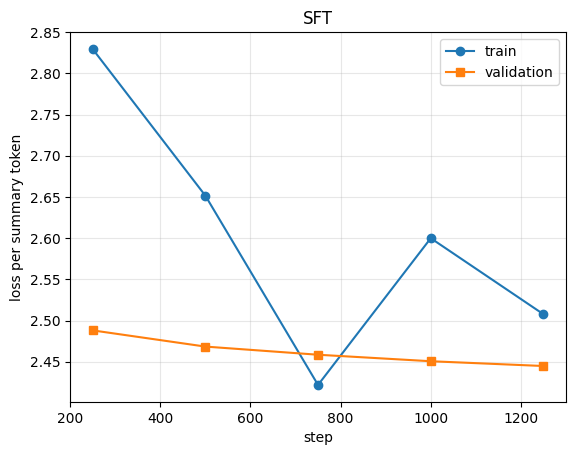

In [17]:
# Figure 1: SFT loss
log = read_jsonl(f"{RESULTS}/sft_log.jsonl")
for r in log: print(r)
plt.plot([r["step"] for r in log], [r["train_loss"] for r in log], "o-", label="train")
plt.plot([r["step"] for r in log], [r["val_loss"] for r in log], "s-", label="validation")
plt.xlabel("step"); plt.ylabel("loss per summary token"); plt.title("SFT"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{FIG}/1_sft_loss.png", dpi=150); plt.show()

In [18]:
# 5 eval posts: base model vs SFT (greedy, 48 tokens)
base = load_causal_lm()
sft = load_causal_lm(f"{CKPT}/sft")
before, after = five_samples(base), five_samples(sft)
for i in range(5):
    print(f"--- post {i+1} ---")
    print("HUMAN:", eval_posts[i]["summary"].strip())
    print("BASE :", before[i].strip())
    print("SFT  :", after[i].strip(), "\n")
del base, sft; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

--- post 1 ---
HUMAN: Boyfriend said some would stuff to me and I am so deeply hurt by them, but I'm scared bringing it up will result in another argument in which he ruins me once more.
BASE : I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going
SFT  : boyfriend said hurtful words to me and I'm still deeply hurt by it. What should I do? 

--- post 2 ---
HUMAN: If we both know we like each other, and have really hit it off, can I just straight up ask her to be my girlfriend?
BASE : I'm not sure if I should ask her to be my girlfriend or not.

I'm not sure if I should ask her to be my girlfriend.

I'm not sure if I should ask her to be my girlfriend.
SFT  : I've been assured that a girl has the same feeling I have, is it alright to just ask her to be my girlfriend? 

--- post 3 ---
HUMAN: Girlfriend broke up and told me "its her fault,i cant love,im not able to bond"
BASE : I don

# Task 3: Stage 2: Reward model

A "judge": post + summary -> **one number**.
SFT transformer body (no LM head) + `nn.Linear(hidden, 1)`, read at the **last real token**.

Bradley-Terry loss (Eq. 40): the human-preferred summary should get the higher score.
$$L = -\mathbb{E}\left[\log \sigma\big(r_\phi(x, y_w) - r_\phi(x, y_l)\big)\right]$$

Settings: 1 epoch, AdamW lr 1e-5, batch 8 pairs.

In [19]:
class RewardModel(nn.Module):
    def __init__(self, lm_path):
        super().__init__()
        lm = load_causal_lm(lm_path)
        self.body = lm.model                                  # transformer only, LM head not used
        self.head = nn.Linear(lm.config.hidden_size, 1)
        nn.init.normal_(self.head.weight, std=1 / lm.config.hidden_size ** 0.5)
        nn.init.zeros_(self.head.bias)
        self._lm = [lm]                                       # only for save_pretrained
        self.to(DEVICE)

    def forward(self, input_ids, attention_mask):
        h = lm_forward(self.body, input_ids, attention_mask).last_hidden_state    # (B, L, H)
        L = attention_mask.shape[1]
        pos = torch.arange(L, device=attention_mask.device).unsqueeze(0)
        last = (pos * attention_mask).argmax(dim=1)          # last REAL token (left or right padding)
        h_last = h[torch.arange(h.shape[0], device=h.device), last]
        return self.head(h_last.float()).squeeze(-1).float()          # (B,)

    def save(self, path):
        os.makedirs(path, exist_ok=True)
        self._lm[0].save_pretrained(path)
        torch.save(self.head.state_dict(), f"{path}/reward_head.pt")

    @classmethod
    def load(cls, path):
        rm = cls(path)
        rm.head.load_state_dict(torch.load(f"{path}/reward_head.pt", map_location=DEVICE))
        return rm

In [20]:
def pair_scores(rm, b):
    rw = rm(b["chosen_ids"].to(DEVICE), b["chosen_mask"].to(DEVICE))
    rl = rm(b["rejected_ids"].to(DEVICE), b["rejected_mask"].to(DEVICE))
    return rw, rl

def bradley_terry_loss(rw, rl):
    return -F.logsigmoid(rw - rl).mean()

@torch.no_grad()
def rm_accuracy(rm, pairs, return_rows=False):
    rm.eval()
    correct, rows = 0, []
    for i in range(0, len(pairs), 16):
        chunk = pairs[i:i + 16]
        rw, rl = pair_scores(rm, collate_pref(chunk, PAD))
        correct += (rw > rl).sum().item()
        for p, a, b in zip(chunk, rw.tolist(), rl.tolist()):
            rows.append({"prompt": p["prompt"], "chosen": p["chosen"], "rejected": p["rejected"],
                         "r_chosen": a, "r_rejected": b, "margin": a - b})
    rm.train()
    return (correct / len(pairs), rows) if return_rows else correct / len(pairs)

TRAIN_RM = not os.path.exists(f"{CKPT}/reward/reward_head.pt")
print("TRAIN_RM =", TRAIN_RM)

TRAIN_RM = False


In [21]:
if TRAIN_RM:
    set_seed()
    rm = RewardModel(f"{CKPT}/sft"); rm.train()
    print("val accuracy before training:", rm_accuracy(rm, pref_val))   # ~50%
    opt = torch.optim.AdamW(rm.parameters(), lr=1e-5)
    loader = DataLoader(pref_train, batch_size=8, shuffle=True, collate_fn=partial(collate_pref, pad_id=PAD))
    LOG = f"{RESULTS}/reward_log.jsonl"; open(LOG, "w").close()
    start, losses, accs = time.time(), [], []

    for step, b in enumerate(loader, 1):
        rw, rl = pair_scores(rm, b)
        loss = bradley_terry_loss(rw, rl)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(rm.parameters(), 1.0)
        opt.step(); opt.zero_grad(set_to_none=True)
        losses.append(loss.item()); accs.append((rw > rl).float().mean().item())

        if step % 250 == 0 or step == len(loader):
            rec = {"step": step, "train_loss": np.mean(losses), "train_acc": np.mean(accs),
                   "val_acc": rm_accuracy(rm, pref_val), "minutes": (time.time() - start) / 60}
            losses, accs = [], []
            log_jsonl(LOG, rec); print(rec)

    rm.save(f"{CKPT}/reward"); tok.save_pretrained(f"{CKPT}/reward")
    log_jsonl(f"{RESULTS}/stage_times.jsonl", {"stage": "Reward model", "minutes": (time.time() - start) / 60,
              "final_train_loss": rec["train_loss"], "val_acc": rec["val_acc"], "gpu": torch.cuda.get_device_name()})
    del rm; torch.cuda.empty_cache()

{'step': 250, 'train_loss': 0.679866, 'train_acc': 0.604, 'val_acc': 0.604, 'minutes': 10.17}
{'step': 500, 'train_loss': 0.649505, 'train_acc': 0.631, 'val_acc': 0.626, 'minutes': 20.41}
{'step': 750, 'train_loss': 0.640231, 'train_acc': 0.6225, 'val_acc': 0.64, 'minutes': 30.68}
{'step': 1000, 'train_loss': 0.622655, 'train_acc': 0.6535, 'val_acc': 0.617, 'minutes': 40.95}
{'step': 1250, 'train_loss': 0.630233, 'train_acc': 0.6475, 'val_acc': 0.631, 'minutes': 51.22}
{'step': 1500, 'train_loss': 0.613281, 'train_acc': 0.6555, 'val_acc': 0.647, 'minutes': 61.48}
{'step': 1750, 'train_loss': 0.599278, 'train_acc': 0.676, 'val_acc': 0.653, 'minutes': 71.8}
{'step': 2000, 'train_loss': 0.614038, 'train_acc': 0.6575, 'val_acc': 0.629, 'minutes': 82.02}
{'step': 2500, 'train_loss': 0.5925559157133102, 'train_acc': None, 'val_acc': 0.631, 'minutes': 102.63826306263606}


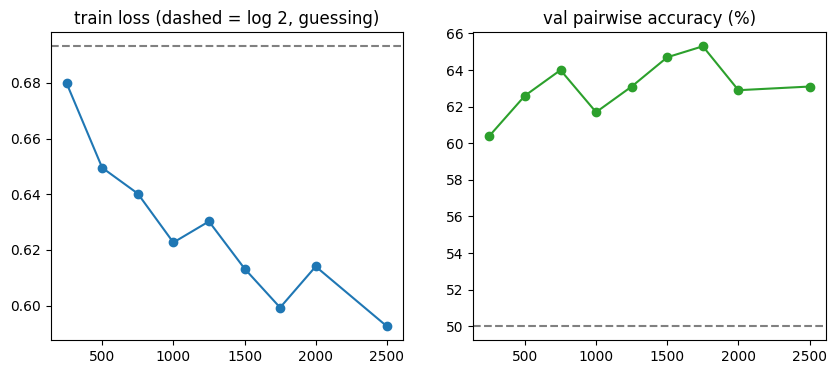

In [23]:
# Figure 2: reward model loss and validation accuracy
log = read_jsonl(f"{RESULTS}/reward_log.jsonl")
for r in log: print(r)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot([r["step"] for r in log], [r["train_loss"] for r in log], "o-"); ax[0].axhline(math.log(2), ls="--", c="gray")
ax[0].set_title("train loss (dashed = log 2, guessing)")
ax[1].plot([r["step"] for r in log], [100 * r["val_acc"] for r in log], "o-", c="C2"); ax[1].axhline(50, ls="--", c="gray")
ax[1].set_title("val pairwise accuracy (%)")
plt.savefig(f"{FIG}/2_reward_model.png", dpi=150); plt.show()

In [24]:
# Final accuracy + 3 pairs it gets most wrong (Task 7.1)
rm = freeze(RewardModel.load(f"{CKPT}/reward"))
acc, rows = rm_accuracy(rm, pref_val, return_rows=True)
print(f"pairwise accuracy on 1000 val pairs: {acc:.3f}")
json.dump(rows, open(f"{RESULTS}/reward_val_scores.json", "w"))
for r in sorted(rows, key=lambda r: r["margin"])[:3]:
    print("\nPOST   :", r["prompt"][-250:].replace("\n", " "))
    print("CHOSEN :", r["chosen"], f"(r={r['r_chosen']:.2f})")
    print("REJECT :", r["rejected"], f"(r={r['r_rejected']:.2f})")
del rm; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/272 [00:01<?, ?it/s]

pairwise accuracy on 1000 val pairs: 0.631

POST   : or who to talk to. I have a few casual friends but no one who would let me vent like I feel I need. No one to come with me. Do i look internally for the support?   Any advice would be great. Thanks reddit. (yep, it's a throwaway, no gw posts). TL;DR:
CHOSEN :  I don't have good friends and I'm losing my mind. I've been depressed for most of my life and now I feel like shit and have no idea what to do. (r=-3.84)
REJECT :  [30F] Cut family out of life and have strained relationship with siblings. I don't know where to go for support or who to talk to. (r=0.49)

POST   : ting older and our sharing said information would just cause them un-necessary discomfort.) SUDDENLY I HAVE TO WALK ON EGG SHELLS TO PROTECT THEIR DELICATE FEELINGS?!?   Reddit, am I wrong to be so pissed with her or should I just play along.? TL;DR:
CHOSEN :  My hater grandparents are getting old; my Mom is now demanding that we be respectful of their age and not upset

# Task 4: Stage 3: PPO

Each generated token = an **action** a_t, state s_t = prompt + tokens so far.

| Model | From | Trained? |
|---|---|---|
| Policy + value head | SFT + new Linear | yes |
| Reference | SFT | frozen |
| Reward model | reward ckpt | frozen |

One iteration: **rollout -> store -> per-token reward -> returns/advantages -> 4 epochs of PPO update**.

In [25]:
# exact settings from the manual
CLIP_EPS, BETA_KL, C_V, C_H, GAMMA = 0.2, 0.05, 0.1, 0.01, 1.0
K_EPOCHS, PPO_LR, N_PROMPTS, N_ITERS = 4, 1e-5, 16, 200
CHUNKS = 2          # split each rollout in 2 halves if memory is short (gradients are added)

class PolicyWithValue(nn.Module):
    def __init__(self, path):
        super().__init__()
        self.lm = load_causal_lm(path)
        self.value_head = nn.Linear(self.lm.config.hidden_size, 1)     # V(s_t)
        nn.init.zeros_(self.value_head.weight); nn.init.zeros_(self.value_head.bias)
        self.to(DEVICE)

def response_stats(lm, full_ids, full_mask, P, value_head=None):
    # only the generated part. hidden at position P-1+t predicts a_t, and V(s_t) is read there too
    h = lm_forward(lm.model, full_ids, full_mask).last_hidden_state[:, P - 1:-1]   # (B, G, H)
    logits = lm.lm_head(h).float()
    logp = gather_logprobs(logits, full_ids[:, P:])
    entropy = torch.logsumexp(logits, -1) - (torch.softmax(logits, -1) * logits).sum(-1)
    values = value_head(h.float()).squeeze(-1).float() if value_head is not None else None
    return logp, entropy, values

In [26]:
def compute_rewards(old_logp, ref_logp, score, m):
    # r_t = -beta * (log pi_old - log pi_ref) + 1[t = T] * r_phi(x, y)
    kl = (old_logp - ref_logp) * m
    rewards = -BETA_KL * kl
    last = (m * torch.arange(m.shape[1], device=m.device)).argmax(1)    # index T of each summary
    rewards[torch.arange(m.shape[0]), last] += score
    return rewards, kl

def compute_returns_advantages(rewards, values, m):
    # R_t = sum of future rewards (gamma = 1),  A_t = R_t - V_old(s_t),  then normalise A
    returns = torch.zeros_like(rewards)
    running = torch.zeros(rewards.shape[0], device=rewards.device)
    for t in reversed(range(rewards.shape[1])):
        running = rewards[:, t] + GAMMA * running * m[:, t]
        returns[:, t] = running
    returns = returns * m
    adv = returns - values
    mu = masked_mean(adv, m)
    std = torch.sqrt(masked_mean((adv - mu) ** 2, m)) + 1e-8
    return returns, ((adv - mu) / std) * m

In [27]:
# tiny check of the reward / return logic on fake numbers (2 summaries, lengths 3 and 2)
m_ = torch.tensor([[1., 1., 1.], [1., 1., 0.]])
r_, _ = compute_rewards(torch.zeros(2, 3), torch.zeros(2, 3), torch.tensor([2.0, -1.0]), m_)
R_, _ = compute_returns_advantages(r_, torch.zeros(2, 3), m_)
print("rewards:", r_.tolist())     # score only at the last real token
print("returns:", R_.tolist())     # gamma = 1 -> every token gets the final score

rewards: [[-0.0, -0.0, 2.0], [-0.0, -1.0, -0.0]]
returns: [[2.0, 2.0, 2.0], [-1.0, -1.0, 0.0]]


In [28]:
TRAIN_PPO = not os.path.exists(f"{CKPT}/ppo/config.json")
print("TRAIN_PPO =", TRAIN_PPO)

TRAIN_PPO = False


In [29]:
if TRAIN_PPO:
    set_seed()
    policy = PolicyWithValue(f"{CKPT}/sft")
    ref = freeze(load_causal_lm(f"{CKPT}/sft"))
    rm = freeze(RewardModel.load(f"{CKPT}/reward"))
    print("frozen check -> reference:", all_frozen(ref), " reward model:", all_frozen(rm))

    opt = torch.optim.AdamW(policy.parameters(), lr=PPO_LR)
    order = list(range(len(sft_train))); random.Random(SEED).shuffle(order)
    LOG = f"{RESULTS}/ppo_log.jsonl"; history = []   # whole log rewritten every iteration (Drive dropped appends once)
    start = time.time()

    for it in range(N_ITERS):
        # 1. ROLLOUT - sample one summary for 16 prompts
        prompts = collate_prompts([sft_train[i] for i in order[it * N_PROMPTS:(it + 1) * N_PROMPTS]], PAD)
        P = prompts["input_ids"].shape[1]
        policy.eval()
        full_ids, full_mask, gen_mask, _ = generate_summaries(policy.lm, prompts, greedy=False)
        full_mask = full_mask.to(DEVICE); m = gen_mask.float().to(DEVICE)

        # 2. STORE (no gradients) + 3. REWARDS + 4. RETURNS / ADVANTAGES
        with torch.no_grad():
            old_logp, _, old_values = response_stats(policy.lm, full_ids, full_mask, P, policy.value_head)
            ref_logp, _, _ = response_stats(ref, full_ids, full_mask, P)
            score = rm(full_ids, full_mask)
            rewards, kl = compute_rewards(old_logp, ref_logp, score, m)
            returns, adv = compute_returns_advantages(rewards, old_values, m)

        # 5. UPDATE - K epochs on the same rollout
        policy.train()
        n_tok, B = m.sum(), m.shape[0]
        step = B // CHUNKS
        st = {"pg_loss": 0, "value_loss": 0, "entropy": 0, "clip_frac": 0}
        ep0_dev, ep0_clip = 0.0, 0.0
        for epoch in range(K_EPOCHS):
            for s in range(0, B, step):
                sl = slice(s, s + step); mm = m[sl]
                new_logp, ent, values = response_stats(policy.lm, full_ids[sl], full_mask[sl], P, policy.value_head)
                ratio = torch.exp(new_logp - old_logp[sl])
                clipped = torch.clamp(ratio, 1 - CLIP_EPS, 1 + CLIP_EPS)
                pg = -(torch.min(ratio * adv[sl], clipped * adv[sl]) * mm).sum() / n_tok
                vf = (((values - returns[sl]) ** 2) * mm).sum() / n_tok
                h = (ent * mm).sum() / n_tok
                loss = pg + C_V * vf - C_H * h
                loss.backward()
                with torch.no_grad():
                    out_frac = (((ratio < 1 - CLIP_EPS) | (ratio > 1 + CLIP_EPS)).float() * mm).sum() / n_tok
                    st["pg_loss"] += pg.item() / K_EPOCHS; st["value_loss"] += vf.item() / K_EPOCHS
                    st["entropy"] += h.item() / K_EPOCHS; st["clip_frac"] += out_frac.item() / K_EPOCHS
                    if epoch == 0:
                        ep0_dev = max(ep0_dev, ((ratio - 1).abs() * mm).max().item())
                        ep0_clip += out_frac.item()
            torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
            opt.step(); opt.zero_grad(set_to_none=True)

        # 6. LOG
        rec = {"iteration": it + 1, "mean_score": score.mean().item(), "mean_kl": kl.sum(1).mean().item(),
               "mean_length": m.sum(1).mean().item(), **st,
               "epoch0_max_abs_ratio_minus_1": ep0_dev, "epoch0_clip_frac": ep0_clip,
               "minutes": (time.time() - start) / 60}
        history.append(rec)
        open(LOG, "w").write("".join(json.dumps(r) + "\n" for r in history))
        if it < 3 or (it + 1) % 10 == 0:
            print({k: round(v, 4) if isinstance(v, float) else v for k, v in rec.items()})

    policy.lm.save_pretrained(f"{CKPT}/ppo"); tok.save_pretrained(f"{CKPT}/ppo")   # value head not saved
    log_jsonl(f"{RESULTS}/stage_times.jsonl", {"stage": "PPO", "minutes": (time.time() - start) / 60,
              "final_train_loss": st["pg_loss"] + C_V * st["value_loss"] - C_H * st["entropy"],
              "final_mean_score": rec["mean_score"], "gpu": torch.cuda.get_device_name()})
    del policy, ref, rm; torch.cuda.empty_cache()

iteration 1 KL to reference      : 0.0 (should be 0)
max |ratio - 1| in epoch 1, ever : 0.0001373291015625 (~0)
clip fraction in epoch 1, ever   : 0.0 (0)


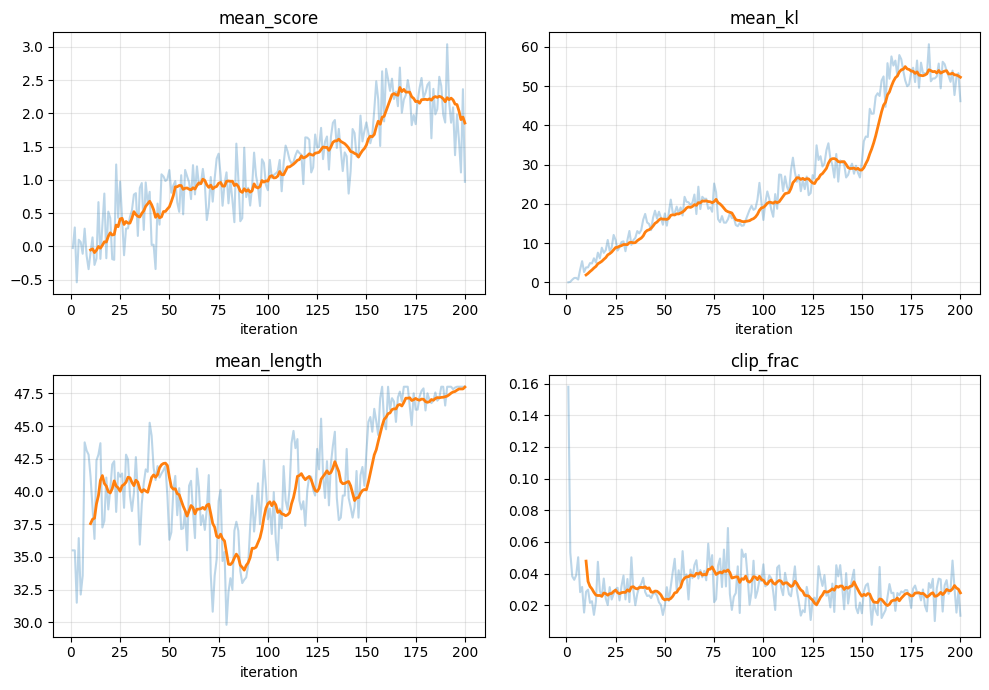

In [30]:
# Correctness checks + Figure 3
log = read_jsonl(f"{RESULTS}/ppo_log.jsonl")
print("iteration 1 KL to reference      :", round(log[0]["mean_kl"], 6), "(should be 0)")
print("max |ratio - 1| in epoch 1, ever :", max(r["epoch0_max_abs_ratio_minus_1"] for r in log), "(~0)")
print("clip fraction in epoch 1, ever   :", max(r["epoch0_clip_frac"] for r in log), "(0)")

it = [r["iteration"] for r in log]
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, k in zip(ax.flat, ["mean_score", "mean_kl", "mean_length", "clip_frac"]):
    y = np.array([r[k] for r in log]); a.plot(it, y, alpha=.3)
    if len(y) >= 10: a.plot(it[9:], np.convolve(y, np.ones(10) / 10, "valid"), lw=2)
    a.set_title(k); a.set_xlabel("iteration"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG}/3_ppo_curves.png", dpi=150); plt.show()

# Task 5: Stage 4: DPO

No reward model, no sampling. Make the chosen summary more likely **relative to the reference** than the rejected one:

$$L_{DPO} = -\mathbb{E}\log\sigma\Big(\beta \log\frac{\pi_\theta(y_w|x)}{\pi_{ref}(y_w|x)} - \beta\log\frac{\pi_\theta(y_l|x)}{\pi_{ref}(y_l|x)}\Big)$$

beta = 0.1, AdamW lr 2e-6, batch 8 pairs, 1 epoch. `log pi(y|x)` = sum over summary tokens only.

In [31]:
BETA_DPO = 0.1

def dpo_margins(policy, ref, b):
    # the value inside sigma(...) for each pair
    d = lambda k: b[k].to(DEVICE)
    pl = b["prompt_lens"]
    with torch.no_grad():
        ref_w = sequence_logprob(ref, d("chosen_ids"), d("chosen_mask"), pl)
        ref_l = sequence_logprob(ref, d("rejected_ids"), d("rejected_mask"), pl)
    pi_w = sequence_logprob(policy, d("chosen_ids"), d("chosen_mask"), pl)
    pi_l = sequence_logprob(policy, d("rejected_ids"), d("rejected_mask"), pl)
    return BETA_DPO * ((pi_w - ref_w) - (pi_l - ref_l))

def dpo_loss(z):
    return -F.logsigmoid(z).mean()

@torch.no_grad()
def dpo_validate(policy, ref):
    policy.eval()
    zs = torch.cat([dpo_margins(policy, ref, b) for b in
                    DataLoader(pref_val, batch_size=16, collate_fn=partial(collate_pref, pad_id=PAD))])
    policy.train()
    return dpo_loss(zs).item(), (zs > 0).float().mean().item()     # loss, implicit reward accuracy

TRAIN_DPO = not os.path.exists(f"{CKPT}/dpo/config.json")
print("TRAIN_DPO =", TRAIN_DPO)

TRAIN_DPO = False


In [32]:
if TRAIN_DPO:
    set_seed()
    policy = load_causal_lm(f"{CKPT}/sft")
    ref = freeze(load_causal_lm(f"{CKPT}/sft"))
    print("frozen check -> reference:", all_frozen(ref))
    opt = torch.optim.AdamW(policy.parameters(), lr=2e-6)
    loader = DataLoader(pref_train, batch_size=8, shuffle=True, collate_fn=partial(collate_pref, pad_id=PAD))
    LOG = f"{RESULTS}/dpo_log.jsonl"; open(LOG, "w").close()
    MICRO = 4
    policy.train(); start, losses = time.time(), []

    for step, b in enumerate(loader, 1):
        total = 0.0
        for s in range(0, 8, MICRO):
            piece = {k: v[s:s + MICRO] for k, v in b.items()}
            z = dpo_margins(policy, ref, piece)
            loss = -F.logsigmoid(z).sum() / len(b["prompt_lens"])
            loss.backward(); total += loss.item()
        if step == 1:
            print(f"first step loss = {total:.4f}   (should be log 2 = {math.log(2):.4f})")
        torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
        opt.step(); opt.zero_grad(set_to_none=True)
        losses.append(total)

        if step % 250 == 0 or step == len(loader):
            vl, va = dpo_validate(policy, ref)
            rec = {"step": step, "train_loss": np.mean(losses), "val_loss": vl, "val_implicit_acc": va,
                   "minutes": (time.time() - start) / 60}
            losses = []; log_jsonl(LOG, rec); print(rec)

    policy.save_pretrained(f"{CKPT}/dpo"); tok.save_pretrained(f"{CKPT}/dpo")
    log_jsonl(f"{RESULTS}/stage_times.jsonl", {"stage": "DPO", "minutes": (time.time() - start) / 60,
              "final_train_loss": rec["train_loss"], "val_implicit_acc": rec["val_implicit_acc"],
              "gpu": torch.cuda.get_device_name()})
    del policy, ref; torch.cuda.empty_cache()

{'step': 250, 'train_loss': 0.6678259218633175, 'val_loss': 0.6692949314117431, 'val_implicit_acc': 0.599, 'minutes': 18.504469641049702}
{'step': 500, 'train_loss': 0.6601214646995067, 'val_loss': 0.6715836486816407, 'val_implicit_acc': 0.611, 'minutes': 37.149921743075055}
{'step': 750, 'train_loss': 0.642448640331626, 'val_loss': 0.6619478001594543, 'val_implicit_acc': 0.598, 'minutes': 55.81808910767237}
{'step': 1000, 'train_loss': 0.6407210388034582, 'val_loss': 0.6575262804031372, 'val_implicit_acc': 0.605, 'minutes': 74.52056773106257}
{'step': 1250, 'train_loss': 0.6313798737078905, 'val_loss': 0.6621374745368958, 'val_implicit_acc': 0.605, 'minutes': 93.14114927053451}
{'step': 1500, 'train_loss': 0.637689667120576, 'val_loss': 0.6653188915252686, 'val_implicit_acc': 0.61, 'minutes': 111.70600480238596}
{'step': 1750, 'train_loss': 0.617238771378994, 'val_loss': 0.6895365190505981, 'val_implicit_acc': 0.601, 'minutes': 130.1642557144165}
{'step': 2000, 'train_loss': 0.6264854

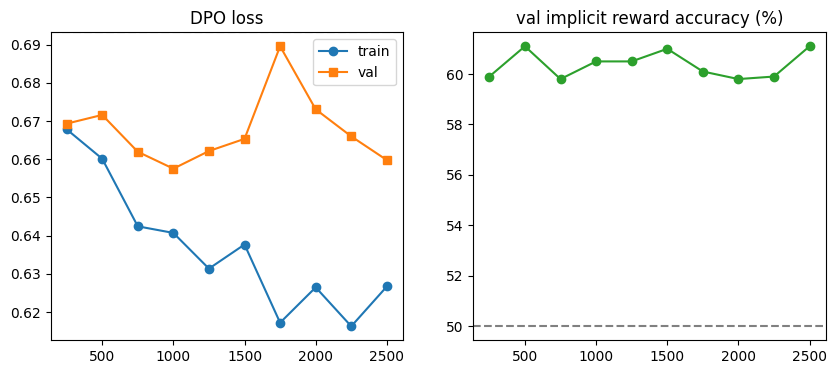

In [33]:
# Figure 4 - DPO
log = read_jsonl(f"{RESULTS}/dpo_log.jsonl")
for r in log: print(r)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot([r["step"] for r in log], [r["train_loss"] for r in log], "o-", label="train")
ax[0].plot([r["step"] for r in log], [r["val_loss"] for r in log], "s-", label="val")
ax[0].axhline(math.log(2), ls="--", c="gray"); ax[0].legend(); ax[0].set_title("DPO loss")
ax[1].plot([r["step"] for r in log], [100 * r["val_implicit_acc"] for r in log], "o-", c="C2")
ax[1].axhline(50, ls="--", c="gray"); ax[1].set_title("val implicit reward accuracy (%)")
plt.savefig(f"{FIG}/4_dpo.png", dpi=150); plt.show()

# Task 6: Compare SFT, PPO, DPO on the 300 evaluation posts

Greedy, max 48 tokens. Metrics: mean r_phi, win rate vs SFT, KL to SFT, length, ROUGE-L.

In [34]:
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
rm = freeze(RewardModel.load(f"{CKPT}/reward"))
sft_ref = freeze(load_causal_lm(f"{CKPT}/sft"))
out = {}
EVAL_FILE = f"{RESULTS}/eval_summaries.jsonl"
REDO_EVAL = not os.path.exists(EVAL_FILE)      # already done by evaluate.py -> just load it
if not REDO_EVAL:
    saved = read_jsonl(EVAL_FILE)
    for name in ["sft", "ppo", "dpo"]:
        out[name] = [{k: r[f"{name}_{k}"] for k in ["summary", "score", "kl", "length", "rougeL"]} for r in saved]
    print("loaded", len(saved), "saved evaluation rows")

for name in (["sft", "ppo", "dpo"] if REDO_EVAL else []):
    model = sft_ref if name == "sft" else freeze(load_causal_lm(f"{CKPT}/{name}"))
    out[name] = []
    for i in range(0, len(eval_posts), 16):
        chunk = eval_posts[i:i + 16]
        batch = collate_prompts(chunk, PAD); P = batch["input_ids"].shape[1]
        full_ids, full_mask, gen_mask, texts = generate_summaries(model, batch)
        full_mask = full_mask.to(DEVICE); plen = torch.full((len(chunk),), P)
        with torch.no_grad():
            score = rm(full_ids, full_mask)
            kl = sequence_logprob(model, full_ids, full_mask, plen) - sequence_logprob(sft_ref, full_ids, full_mask, plen)
        for e, t, s, k, n in zip(chunk, texts, score.tolist(), kl.tolist(), gen_mask.sum(1).tolist()):
            out[name].append({"summary": t.strip(), "score": s, "kl": k, "length": n,
                              "rougeL": scorer.score(e["summary"].strip(), t.strip())["rougeL"].fmeasure})
    print(name, "done")
    if name != "sft": del model; torch.cuda.empty_cache()

if REDO_EVAL:
  with open(EVAL_FILE, "w") as f:
    for i, e in enumerate(eval_posts):
        row = {"id": i, "post": e["prompt"], "reference": e["summary"].strip()}
        for name in out:
            row.update({f"{name}_{k}": v for k, v in out[name][i].items()})
        f.write(json.dumps(row) + "\n")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

loaded 300 saved evaluation rows


In [35]:
# Table 3
sft_s = np.array([r["score"] for r in out["sft"]])
lines = ["| Policy | Mean r_phi | Win rate vs SFT | KL to SFT | Length | ROUGE-L |", "|---|---|---|---|---|---|"]
for name in out:
    s = np.array([r["score"] for r in out[name]])
    win = "-" if name == "sft" else f"{100 * (s > sft_s).mean():.1f}%"
    lines.append(f"| {name.upper()} | {s.mean():.3f} | {win} | {np.mean([r['kl'] for r in out[name]]):.3f} | "
                 f"{np.mean([r['length'] for r in out[name]]):.1f} | {np.mean([r['rougeL'] for r in out[name]]):.3f} |")
table3 = "\n".join(lines); print(table3)
open(f"{RESULTS}/table3_comparison.md", "w").write(table3)

| Policy | Mean r_phi | Win rate vs SFT | KL to SFT | Length | ROUGE-L |
|---|---|---|---|---|---|
| SFT | -0.475 | - | 0.000 | 29.7 | 0.253 |
| PPO | 0.208 | 67.3% | 12.566 | 46.3 | 0.200 |
| DPO | 0.438 | 70.7% | 2.704 | 44.0 | 0.237 |


237

In [36]:
# Table 2: training summary (from what each stage logged)
times = {r["stage"]: r for r in read_jsonl(f"{RESULTS}/stage_times.jsonl")}
sft_val_loss = read_jsonl(f"{RESULTS}/sft_log.jsonl")[-1]["val_loss"]
metric = {"SFT": f"val loss {sft_val_loss:.3f}",
          "Reward model": f"pairwise acc {100 * times['Reward model']['val_acc']:.1f}%",
          "PPO": f"final mean r_phi {times['PPO']['final_mean_score']:.3f}",
          "DPO": f"implicit reward acc {100 * times['DPO']['val_implicit_acc']:.1f}%"}
t2 = ["| Stage | Final train loss | Validation metric | Time / GPU |", "|---|---|---|---|"]
for st in metric:
    t2.append(f"| {st} | {times[st]['final_train_loss']:.4f} | {metric[st]} | {times[st]['minutes']:.0f} min / {times[st]['gpu']} |")
print("\n".join(t2)); open(f"{RESULTS}/table2_training.md", "w").write("\n".join(t2))

| Stage | Final train loss | Validation metric | Time / GPU |
|---|---|---|---|
| SFT | 2.5076 | val loss 2.445 | 71 min / Tesla T4 |
| Reward model | 0.5926 | pairwise acc 63.1% | 103 min / Tesla T4 |
| PPO | 0.1364 | final mean r_phi 0.971 | 50 min / Tesla T4 |
| DPO | 0.6267 | implicit reward acc 61.1% | 186 min / Tesla T4 |


329

In [37]:
# posts where PPO/DPO gained or lost the most reward vs SFT -> read them and pick 10 for samples.md
gain = sorted(range(300), key=lambda i: max(out["ppo"][i]["score"], out["dpo"][i]["score"]) - out["sft"][i]["score"])
for i in gain[-3:] + gain[:3]:
    print(f"\n=== post {i} ===\n", eval_posts[i]["prompt"][-300:])
    print("HUMAN:", eval_posts[i]["summary"].strip())
    for name in out:
        print(f"{name.upper():4}: (r={out[name][i]['score']:.2f})", out[name][i]["summary"])


=== post 215 ===
 ny reason. We fought for the next 2 hours and she finally busted this one out....
"it is me or marijuana", I told her I can't work with that ultimatum.. her last straw.. now she told me I have 12 hours to move out of our apartment and she tossed the engagement ring at my face.. What do I do..
TL;DR:
HUMAN: Ultimatum to never use weed in anyway ever again, said no, fiance threw ring in my face and demanded me to move out.
SFT : (r=-4.81)  I have smoked weed 2 times in the last year and I am 23 years old. I have a big issue with the culture and people surrounding the drug. I am 23 years old and I am going to move out
PPO : (r=1.10)  My fiance smoked weed twice last weekend with friends and I collapsed on her couch after the explosion and demanded that I never smoke weed again and moved out of our apartment after the explosion.. what do I do..
DPO : (r=-1.97)  My fiance has smoked weed 2 times in the last year and has demanded that I never have edibles or vape again and

# Human evaluation (30 posts, blind)

1. Run the next cell -> it makes `human_eval.csv` on Drive with summaries shuffled as A / B / C.
2. Each member opens it (Google Sheets) and fills `member1_pick` / `member2_pick` **without discussing**.
3. Run the cell after it to get Table 4.

In [43]:
import csv
if os.path.exists(f"{RESULTS}/human_eval.csv"):
    print("human_eval.csv already exists - not overwriting our picks")
else:
    rng = random.Random(2026)
    chosen = rng.sample(range(300), 30)
    key = {}
    with open(f"{RESULTS}/human_eval.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["post_id", "post", "A", "B", "C", "member1_pick", "member2_pick"])
        for pid in chosen:
            models = ["sft", "ppo", "dpo"]; rng.shuffle(models)
            key[str(pid)] = dict(zip("ABC", models))
            w.writerow([pid, eval_posts[pid]["prompt"], *[out[mdl][pid]["summary"] for mdl in models], "", ""])
    json.dump(key, open(f"{RESULTS}/human_eval_key.json", "w"))
    print("sheet saved -> fill it, then run the next cell")

human_eval.csv already exists - not overwriting our picks


In [44]:
# Table 4 (download the filled sheet as CSV and put it back at the same path first)
key = json.load(open(f"{RESULTS}/human_eval_key.json"))
counts = {"Member 1": {"sft": 0, "ppo": 0, "dpo": 0}, "Member 2": {"sft": 0, "ppo": 0, "dpo": 0}}
agree = n = 0
for row in csv.DictReader(open(f"{RESULTS}/human_eval.csv")):
    p1, p2 = row["member1_pick"].strip().upper(), row["member2_pick"].strip().upper()
    if p1 not in ("A", "B", "C") or p2 not in ("A", "B", "C"):
        continue
    counts["Member 1"][key[row["post_id"]][p1]] += 1
    counts["Member 2"][key[row["post_id"]][p2]] += 1
    agree += p1 == p2; n += 1
t4 = ["| | SFT picked | PPO picked | DPO picked |", "|---|---|---|---|"]
t4 += [f"| {mem} | {c['sft']} | {c['ppo']} | {c['dpo']} |" for mem, c in counts.items()]
t4.append(f"\nAgreement between members: {agree} / {n}")
print("\n".join(t4)); open(f"{RESULTS}/table4_human_eval.md", "w").write("\n".join(t4))

| | SFT picked | PPO picked | DPO picked |
|---|---|---|---|
| Member 1 | 16 | 1 | 13 |
| Member 2 | 7 | 7 | 16 |

Agreement between members: 19 / 30


149

# Task 8 - Front end (Gradio)

Paste a post -> SFT, PPO, DPO summaries side by side with the reward-model score. Opens a public link, take the screenshot from there.

In [42]:
import gradio as gr

policies = {n: freeze(load_causal_lm(f"{CKPT}/{n}")) for n in ["sft", "ppo", "dpo"]}
rm = freeze(RewardModel.load(f"{CKPT}/reward"))

def summarise(subreddit, title, body):
    prompt = clean_post(f"SUBREDDIT: r/{subreddit}\nTITLE: {title}\nPOST: {body}")
    ids = tok(prompt, add_special_tokens=False)["input_ids"][-MAX_PROMPT_TOKENS:]
    batch = collate_prompts([{"prompt_ids": ids}], PAD)
    res = []
    for model in policies.values():
        full_ids, full_mask, _, texts = generate_summaries(model, batch)
        res += [texts[0].strip(), f"{rm(full_ids, full_mask.to(DEVICE)).item():+.3f}"]
    return res

with gr.Blocks(title="RLHF TL;DR") as demo:
    gr.Markdown("## SFT vs PPO vs DPO - TL;DR summaries (SmolLM2-135M)")
    with gr.Row():
        sub = gr.Textbox(label="Subreddit", value="relationships")
        title = gr.Textbox(label="Title", value="My boyfriend keeps forgetting our plans")
    body = gr.Textbox(label="Post", lines=6, value="We've been together two years. Lately he forgets almost every plan we make. When I bring it up he says he's stressed at work and I'm overreacting. How do I talk to him without starting a fight?")
    btn = gr.Button("Summarise", variant="primary")
    outs = []
    with gr.Row():
        for name in ["SFT", "PPO", "DPO"]:
            with gr.Column():
                gr.Markdown(f"### {name}")
                outs += [gr.Textbox(label="summary", lines=4), gr.Textbox(label="reward score")]
    btn.click(summarise, [sub, title, body], outs)

demo.launch(share=True)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:02<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://979eb535a9aa8e929b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
